In [ ]:
import pandas as pd


In [125]:
# Cargar el CSV
df = pd.read_csv("./dataset_aries/data.csv")


In [126]:
# ── Resumen general ──────────────────────────────────────
print(df.shape)          # Filas y columnas: (1000, 12)
print(df.dtypes)         # Tipo de dato por columna
print(df.head())         # Primeras 5 filas
print(df.tail())         # Últimas 5 filas

# ── Estadísticas descriptivas ────────────────────────────
print(df.describe())     # count, mean, std, min, max... de columnas numéricas
print(df.describe(include="all"))  # Incluye columnas de texto también

# ── Valores nulos ────────────────────────────────────────
print(df.isnull().sum())           # Nulos por columna
print(df.isnull().sum() / len(df)) # Porcentaje de nulos

# ── Valores únicos ───────────────────────────────────────
print(df.nunique())                # Cuántos valores únicos por columna
print(df["data_source"].value_counts())# Frecuencia de valores en una columna

(76987, 8)
Unnamed: 0            int64
data_source          object
argument             object
proposition_1        object
proposition_2        object
relations             int64
start_end_indexes    object
all_relations        object
dtype: object
   Unnamed: 0 data_source                                           argument  \
0           0        ACSP   humans are exceptionally sensitive to the sli...   
1           1        ACSP   19 '[SEP]' The problem of simulating the beha...   
2           2        ACSP   Several challenges remain '[SEP]' An optimiza...   
3           3        CDCP   I'm a physician, epidemiologist, and mother t...   
4           4      US2016   I hate that I like TRUMP's realness '[SEP]' n...   

                                       proposition_1  \
0                            and statistical methods   
1  By modifying the significance of this componen...   
2                           Cohen and his colleagues   
3  Which in a severe anaphylactic reaction is 

In [127]:
# Clean data
df["proposition_1"] = df["proposition_1"].str.strip() 
df["proposition_2"] = df["proposition_2"].str.strip()

In [128]:
columna = "data_source"
# Opción 1 - value_counts (más simple, solo una columna)
# print(df[columna].value_counts())

# Opción 2 - groupby + count (más flexible)
# print(df.groupby(columna).size().reset_index(name="cantidad"))

# Opción 3 - con porcentaje incluido
conteo = df[columna].value_counts().reset_index()
conteo.columns = ["valor", "cantidad"]
conteo["porcentaje"] = (conteo["cantidad"] / len(df) * 100).round(2)
print(conteo)

       valor  cantidad  porcentaje
0       ACSP     26298       34.16
1       AAEC     16014       20.80
2     US2016     10893       14.15
3     Cuties      9777       12.70
4   ABstRACT      7215        9.37
5   US2016R1      3369        4.38
6       CDCP      2328        3.02
7  Microtext      1093        1.42


In [129]:
# Filtrar por un valor específico
df_filtrado = df[df[columna] == "AAEC"]

# Filtrar por texto parcial en la columna "argument"
df_resultado = df_filtrado[df_filtrado["argument"].str.contains("hat after working out,", na=False)]
df_resultado = df_resultado[df_resultado["relations"] != 0]
df_resultado = df_resultado.sort_values("proposition_1")

print(df_resultado.shape)

df_resultado

(15, 8)


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations
55142,55142,AAEC,"reducing stress by listening to music, playin...",I feel happy when I listen music,I could enjoy listening music without thinking...,1,"[(36, 46)]",[('I could enjoy listening music without think...
65477,65477,AAEC,"reducing stress by listening to music, playin...",Meditation is easy way to relax,"it is not require any equipment, and it take f...",1,"[(148, 159)]","[('it is not require any equipment, and it tak..."
23924,23924,AAEC,"reducing stress by listening to music, playin...",another way that is perfectly work for everyon...,"I feel that after working out, I am easily to ...",1,"[(89, 102), (106, 118), (122, 135)]","[('after work, I always do exercise, and joggi..."
26620,26620,AAEC,"reducing stress by listening to music, playin...",another way that is perfectly work for everyon...,"after work, I always do exercise, and jogging ...",1,"[(89, 102), (106, 118), (122, 135)]","[('after work, I always do exercise, and joggi..."
42849,42849,AAEC,"reducing stress by listening to music, playin...",another way that is perfectly work for everyon...,Exercising not only reduce my stress but also ...,1,"[(89, 102), (106, 118), (122, 135)]","[('after work, I always do exercise, and joggi..."
49163,49163,AAEC,"reducing stress by listening to music, playin...","it is not require any equipment, and it take f...",A way to do meditation is that I just sit down...,1,"[(163, 182)]",[('A way to do meditation is that I just sit d...
51885,51885,AAEC,"reducing stress by listening to music, playin...",listening to music is a great way to relax,I always listen music from my mp3 player,1,"[(50, 56), (25, 32)]","[('I feel happy when I listen music', 'Default..."
59723,59723,AAEC,"reducing stress by listening to music, playin...",listening to music is a great way to relax,I feel happy when I listen music,1,"[(50, 56), (25, 32)]","[('I feel happy when I listen music', 'Default..."
9724,9724,AAEC,"reducing stress by listening to music, playin...",meditation also one of the ways to reduce the ...,These could relieve me from stress,1,"[(139, 144), (186, 191)]","[('Meditation is easy way to relax', 'Default ..."
69742,69742,AAEC,"reducing stress by listening to music, playin...",meditation also one of the ways to reduce the ...,Meditation is easy way to relax,1,"[(139, 144), (186, 191)]","[('Meditation is easy way to relax', 'Default ..."


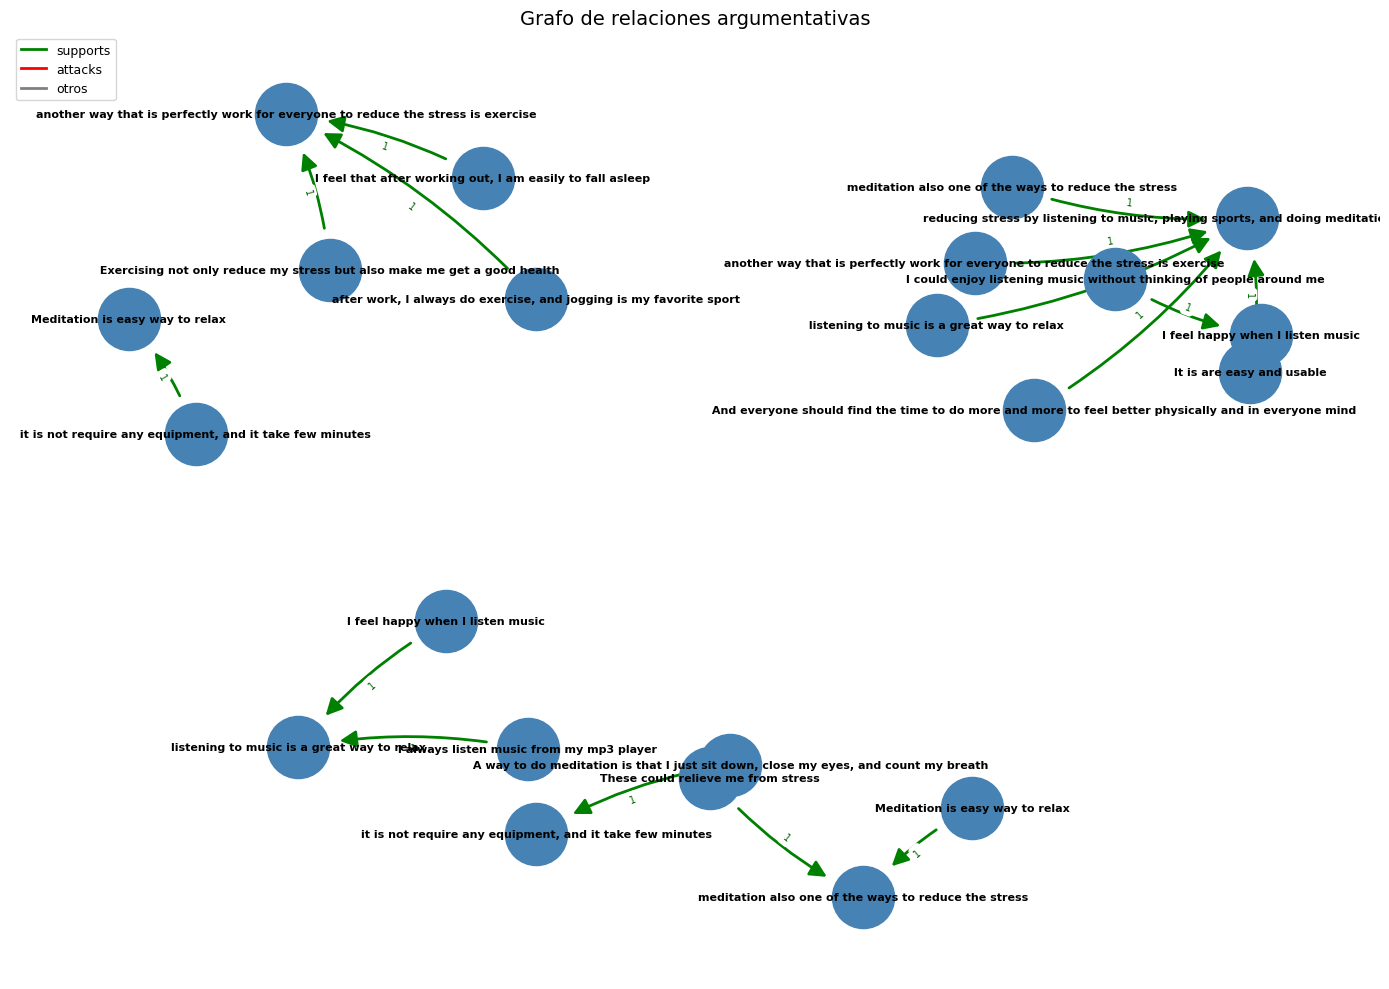

In [93]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Crear grafo dirigido
G = nx.DiGraph()

# Agregar aristas
for _, row in df_resultado.iterrows():
    G.add_edge(row["proposition_2"], row["proposition_1"], label=row["relations"])

# Colores por tipo de relación
colores_label = {1: "green", 2: "red"}
edge_colors = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]

# ── Graficar ─────────────────────────────────────────────
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42, k=0.5)

# Nodos
nx.draw_networkx_nodes(G, pos, node_color="steelblue", node_size=2000)
nx.draw_networkx_labels(G, pos, font_color="black", font_size=8, font_weight="bold")

# Aristas con flechas
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=25,
    arrowstyle="-|>",          # Estilo de flecha
    width=2,                    # Grosor de línea
    connectionstyle="arc3,rad=0.1",  # Curvatura para ver mejor las flechas
    min_source_margin=30,       # Margen para que la flecha no tape el nodo
    min_target_margin=30,
)

# Etiquetas de aristas
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7,
    font_color="darkgreen"
)

# Leyenda
from matplotlib.lines import Line2D
leyenda = [
    Line2D([0], [0], color="green", linewidth=2, label="supports"),
    Line2D([0], [0], color="red",   linewidth=2, label="attacks"),
    Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
]
plt.legend(handles=leyenda, loc="upper left", fontsize=9)

plt.title("Grafo de relaciones argumentativas", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()

In [60]:
valor = df_resultado.loc[55142, "argument"]
texto_formateado = valor.replace("[SEP]", "\n[SEP]")

print(texto_formateado)

 reducing stress by listening to music, playing sports, and doing meditation are easy and practical ways '
[SEP]' I always listen music from my mp3 player '
[SEP]' I could enjoy listening music without thinking of people around me '
[SEP]' I feel happy when I listen music '
[SEP]' listening to music is a great way to relax '
[SEP]' another way that is perfectly work for everyone to reduce the stress is exercise '
[SEP]' after work, I always do exercise, and jogging is my favorite sport '
[SEP]' I feel that after working out, I am easily to fall asleep '
[SEP]' Exercising not only reduce my stress but also make me get a good health '
[SEP]' Meditation is easy way to relax '
[SEP]' it is not require any equipment, and it take few minutes '
[SEP]' A way to do meditation is that I just sit down, close my eyes, and count my breath '
[SEP]' These could relieve me from stress '
[SEP]' meditation also one of the ways to reduce the stress '
[SEP]' listening to music, exercising, and doing medit

In [31]:
# Cargar el CSV
dfv_train = pd.read_csv("./New Preprocessed/component_train.csv")
dfv_test = pd.read_csv("./New Preprocessed/component_test.csv")
dfv_value = pd.read_csv("./New Preprocessed/component_val.csv")

In [94]:
dfv = dfv_train

dfv_resultado_component = dfv[dfv["text_tokens"].str.contains("hat after working out,", na=False)]
dfv_resultado_component

,Unnamed: 0,text_id,component_tokens,text_tokens,labels
3054,3366,AAEC_282,"reducing stress by listening to music, playing...",Best ways of reducing stress: listening to mus...,MajorClaim
3055,3367,AAEC_282,I always listen music from my mp3 player,Best ways of reducing stress: listening to mus...,Premise
3056,3368,AAEC_282,I could enjoy listening music without thinking...,Best ways of reducing stress: listening to mus...,Premise
3057,3369,AAEC_282,I feel happy when I listen music,Best ways of reducing stress: listening to mus...,Premise
3058,3370,AAEC_282,listening to music is a great way to relax,Best ways of reducing stress: listening to mus...,Claim
3059,3371,AAEC_282,another way that is perfectly work for everyon...,Best ways of reducing stress: listening to mus...,Claim
3060,3372,AAEC_282,"after work, I always do exercise, and jogging ...",Best ways of reducing stress: listening to mus...,Premise
3061,3373,AAEC_282,"I feel that after working out, I am easily to ...",Best ways of reducing stress: listening to mus...,Premise
3062,3374,AAEC_282,Exercising not only reduce my stress but also ...,Best ways of reducing stress: listening to mus...,Premise
3063,3375,AAEC_282,Meditation is easy way to relax,Best ways of reducing stress: listening to mus...,Premise


In [70]:
# Cargar el CSV
dfr = pd.read_csv("./New Preprocessed/relation_train.csv")

In [95]:
dfv_resultado_relation = dfr[dfr["text_id"] == "AAEC_282"]
dfv_resultado_relation = dfv_resultado_relation.dropna()
dfv_resultado_relation = dfv_resultado_relation.sort_values("source_tokens")
print(dfv_resultado_relation.shape)
dfv_resultado_relation

(20, 7)


,Unnamed: 0,text_id,source_id,source_tokens,target_id,target_tokens,labels
49186,53974,AAEC_282,T12,A way to do meditation is that I just sit down...,T11,"it is not require any equipment, and it take f...",supports
49199,53987,AAEC_282,T17,And everyone should find the time to do more a...,T15,"listening to music, exercising, and doing medi...",support
49198,53986,AAEC_282,T17,And everyone should find the time to do more a...,T1,"reducing stress by listening to music, playing...",support
49185,53973,AAEC_282,T9,Exercising not only reduce my stress but also ...,T6,another way that is perfectly work for everyon...,supports
49182,53970,AAEC_282,T2,I always listen music from my mp3 player,T5,listening to music is a great way to relax,supports
49180,53968,AAEC_282,T3,I could enjoy listening music without thinking...,T4,I feel happy when I listen music,supports
49181,53969,AAEC_282,T4,I feel happy when I listen music,T5,listening to music is a great way to relax,supports
49184,53972,AAEC_282,T8,"I feel that after working out, I am easily to ...",T6,another way that is perfectly work for everyon...,supports
49196,53984,AAEC_282,T16,It is are easy and usable,T1,"reducing stress by listening to music, playing...",support
49197,53985,AAEC_282,T16,It is are easy and usable,T15,"listening to music, exercising, and doing medi...",support


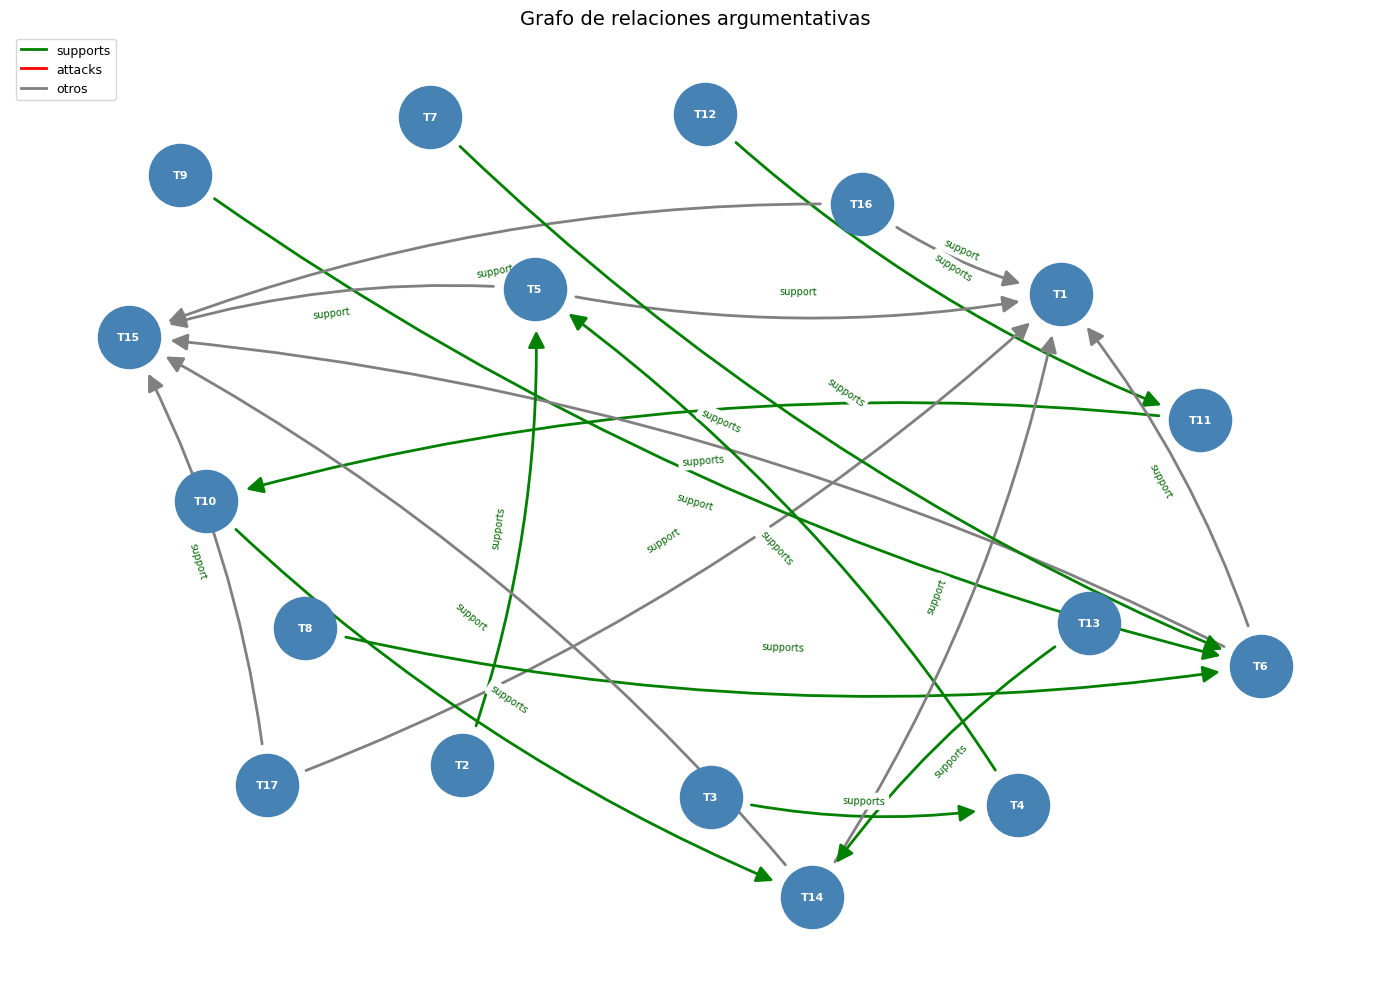

In [96]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Crear grafo dirigido
G = nx.DiGraph()

# Agregar aristas
for _, row in dfv_resultado_relation.iterrows():
    G.add_edge(row["source_id"], row["target_id"], label=row["labels"])

# Colores por tipo de relación
colores_label = {"supports": "green", "attacks": "red"}
edge_colors = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]

# ── Graficar ─────────────────────────────────────────────
plt.figure(figsize=(14, 10))

# pos = nx.spring_layout(G, seed=42)
pos = nx.spring_layout(G, seed=42, k=1, iterations=10)

# Nodos
nx.draw_networkx_nodes(G, pos, node_color="steelblue", node_size=2000)
nx.draw_networkx_labels(G, pos, font_color="white", font_size=8, font_weight="bold")

# Aristas con flechas
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=25,
    arrowstyle="-|>",          # Estilo de flecha
    width=2,                    # Grosor de línea
    connectionstyle="arc3,rad=0.1",  # Curvatura para ver mejor las flechas
    min_source_margin=30,       # Margen para que la flecha no tape el nodo
    min_target_margin=30,
)

# Etiquetas de aristas
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7,
    font_color="darkgreen"
)

# Leyenda
from matplotlib.lines import Line2D
leyenda = [
    Line2D([0], [0], color="green", linewidth=2, label="supports"),
    Line2D([0], [0], color="red",   linewidth=2, label="attacks"),
    Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
]
plt.legend(handles=leyenda, loc="upper left", fontsize=9)

plt.title("Grafo de relaciones argumentativas", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()

In [100]:
# Preparar dfv_resultado_component con solo las columnas necesarias
df_component = dfv_resultado_component[["component_tokens", "labels"]].copy()

# Merge para obtener labels del SOURCE
df_merged = dfv_resultado_relation.merge(
    df_component.rename(columns={
        "component_tokens": "source_tokens",
        "labels": "labels_component_source"
    }),
    on="source_tokens",
    how="left"
)

# Merge para obtener labels del TARGET
df_merged = df_merged.merge(
    df_component.rename(columns={
        "component_tokens": "target_tokens",
        "labels": "labels_component_target"
    }),
    on="target_tokens",
    how="left"
)

# Renombrar labels de la relación
df_merged = df_merged.rename(columns={"labels": "labels_relation"})

# Seleccionar solo las columnas que necesitas
df_nuevo = df_merged[[
    "source_id",
    "target_id",
    "labels_relation",
    "labels_component_source",
    "labels_component_target"
]]

# print(df_nuevo.head())
print(df_nuevo.shape)

df_nuevo

(20, 5)


,source_id,target_id,labels_relation,labels_component_source,labels_component_target
0,T12,T11,supports,Premise,Premise
1,T17,T15,support,Claim,MajorClaim
2,T17,T1,support,Claim,MajorClaim
3,T9,T6,supports,Premise,Claim
4,T2,T5,supports,Premise,Claim
5,T3,T4,supports,Premise,Premise
6,T4,T5,supports,Premise,Claim
7,T8,T6,supports,Premise,Claim
8,T16,T1,support,Claim,MajorClaim
9,T16,T15,support,Claim,MajorClaim


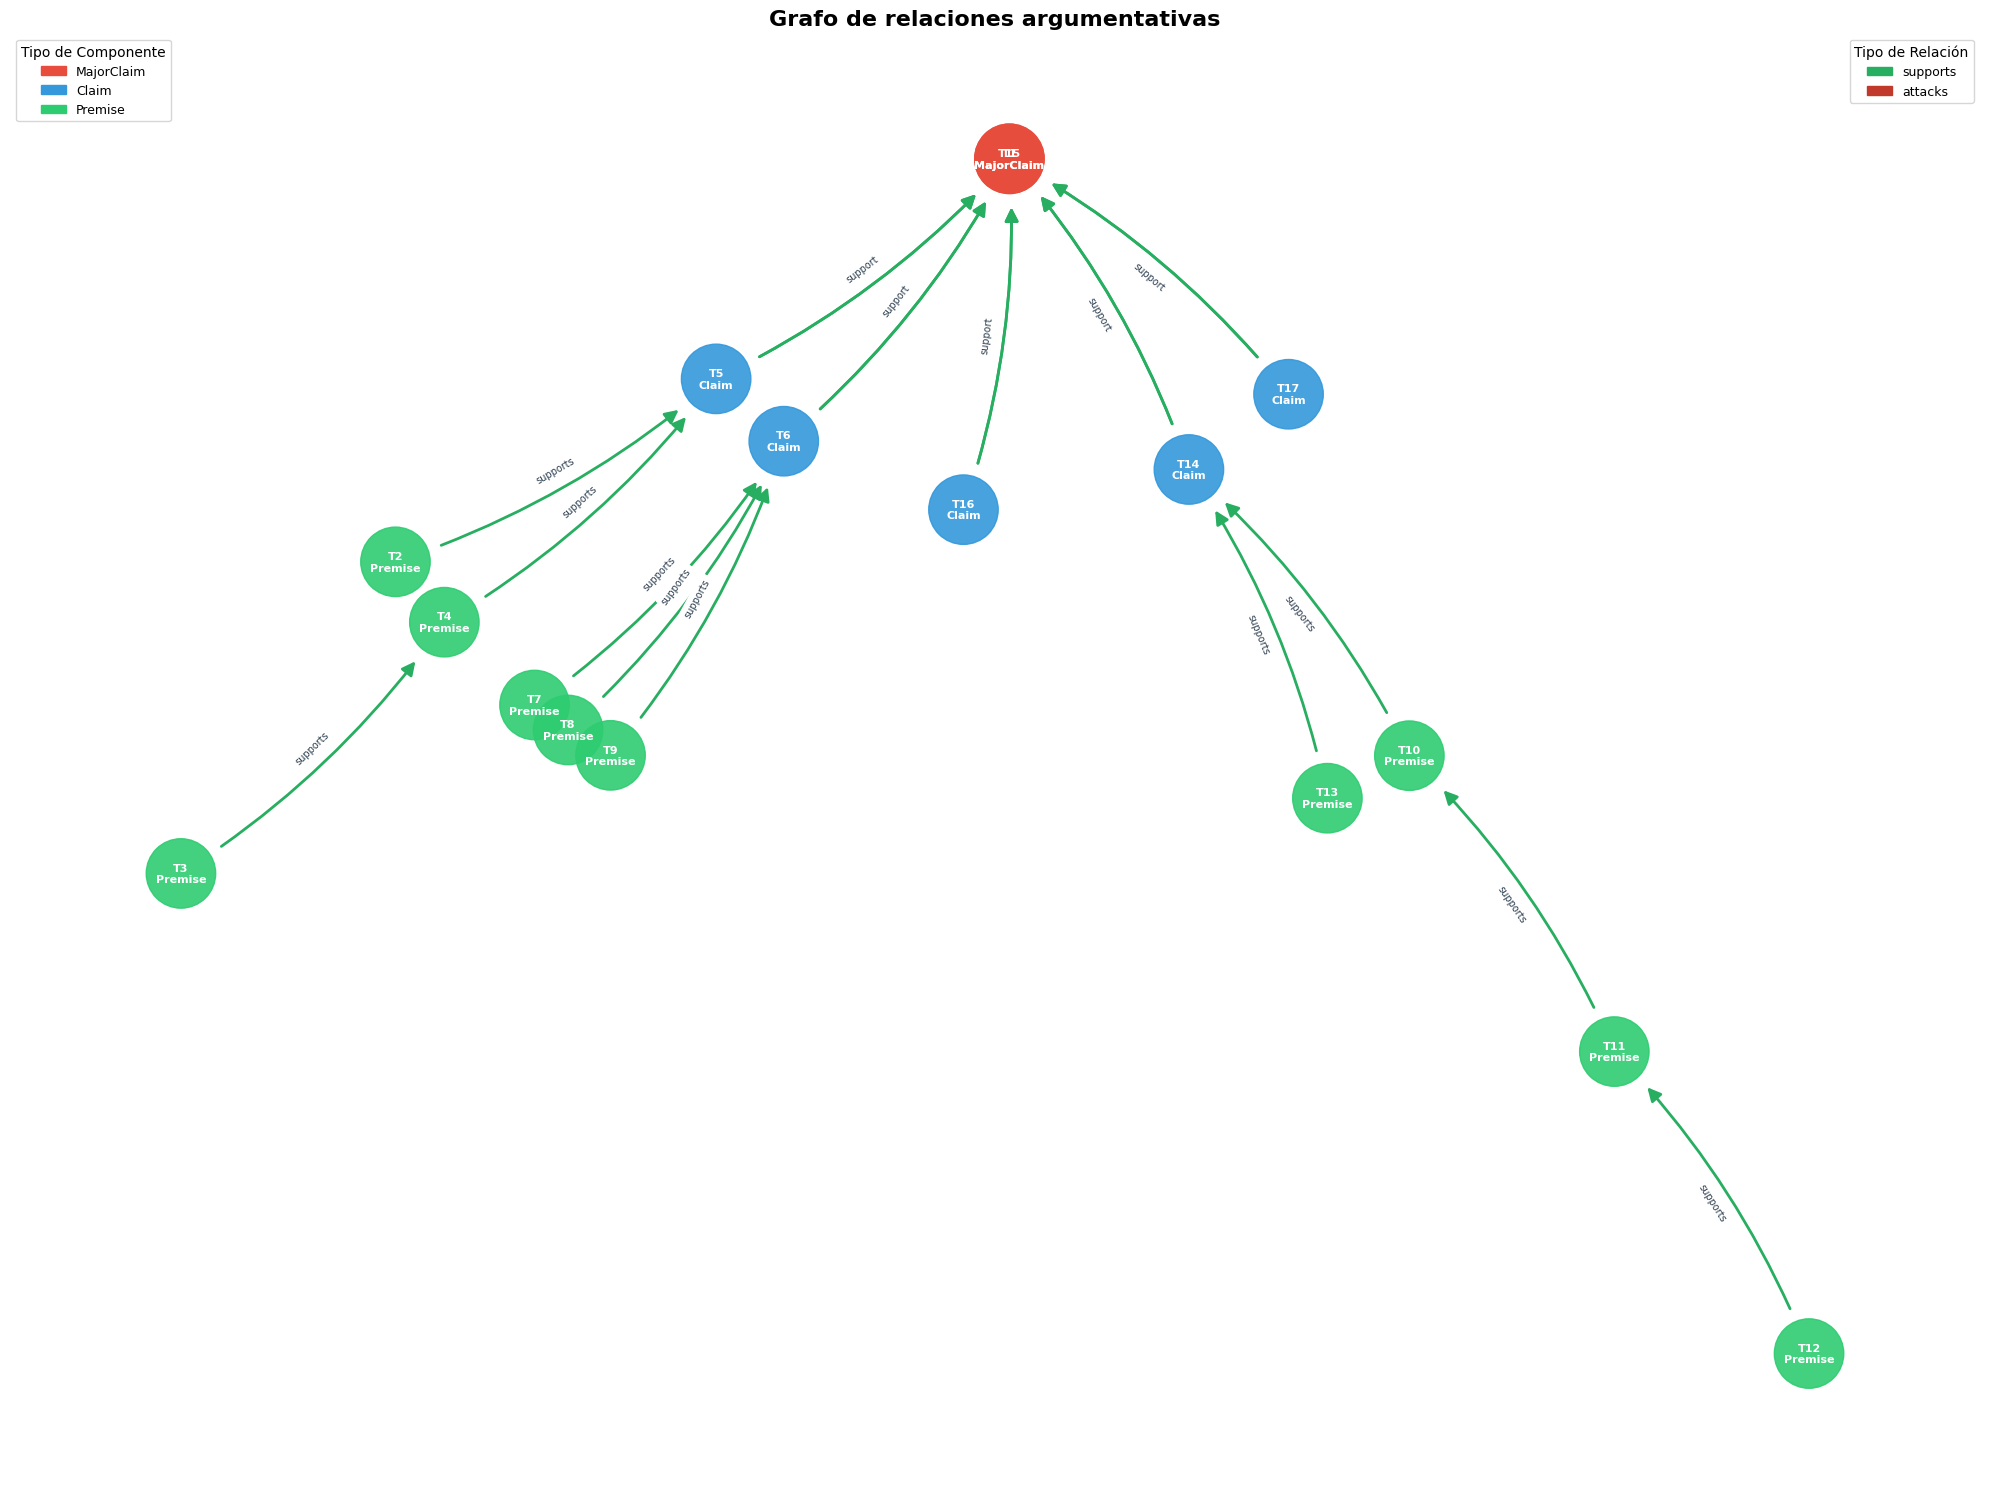

In [99]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Crear grafo ───────────────────────────────────────────
G = nx.DiGraph()

for _, row in df_nuevo.iterrows():
    G.add_edge(row["source_id"], row["target_id"], label=row["labels_relation"])
    G.nodes[row["source_id"]]["component"] = row["labels_component_source"]
    G.nodes[row["target_id"]]["component"] = row["labels_component_target"]

# ── Colores por tipo de componente (nodo) ─────────────────
color_nodo = {
    "MajorClaim" : "#e74c3c",   # Rojo
    "Claim"      : "#3498db",   # Azul
    "Premise"    : "#2ecc71",   # Verde
}

node_colors = [
    color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
    for n in G.nodes()
]

# ── Colores por tipo de relación (arista) ─────────────────
color_arista = {
    "supports" : "#27ae60",   # Verde oscuro
    "support"  : "#27ae60",   # Verde oscuro (misma relación diferente escritura)
    "attacks"  : "#c0392b",   # Rojo oscuro
}

edge_colors = [
    color_arista.get(d["label"], "#7f8c8d")
    for _, _, d in G.edges(data=True)
]

# ── Layout ────────────────────────────────────────────────
plt.figure(figsize=(20, 15))
pos = nx.kamada_kawai_layout(G)

# ── Dibujar nodos ─────────────────────────────────────────
nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=2500,
    alpha=0.9
)

# Etiquetas de nodos con ID + tipo de componente
node_labels = {
    n: f"{n}\n{G.nodes[n].get('component', '')}"
    for n in G.nodes()
}
nx.draw_networkx_labels(
    G, pos,
    labels=node_labels,
    font_size=8,
    font_color="white",
    font_weight="bold"
)

# ── Dibujar aristas ───────────────────────────────────────
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=20,
    width=2,
    connectionstyle="arc3,rad=0.1",
    min_source_margin=35,
    min_target_margin=35,
)

# Etiquetas de aristas
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7,
    font_color="#2c3e50"
)

# ── Leyenda ───────────────────────────────────────────────
leyenda_nodos = [
    mpatches.Patch(color="#e74c3c", label="MajorClaim"),
    mpatches.Patch(color="#3498db", label="Claim"),
    mpatches.Patch(color="#2ecc71", label="Premise"),
]
leyenda_aristas = [
    mpatches.Patch(color="#27ae60", label="supports"),
    mpatches.Patch(color="#c0392b", label="attacks"),
]

legend1 = plt.legend(
    handles=leyenda_nodos,
    title="Tipo de Componente",
    loc="upper left",
    fontsize=9,
    title_fontsize=10
)
plt.gca().add_artist(legend1)
plt.legend(
    handles=leyenda_aristas,
    title="Tipo de Relación",
    loc="upper right",
    fontsize=9,
    title_fontsize=10
)

plt.title("Grafo de relaciones argumentativas", fontsize=16, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

### Dataset Microtext

In [130]:
df_microtext = df[df[columna] == "Microtext"]
print(df_microtext.shape)
df_microtext

(1093, 8)


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations
202,202,Microtext,Supermarket employees and people who work in ...,Hence it is good when shops are not open on Su...,Likewise public holidays should remain what th...,1,"[(4, 22), (26, 61), (83, 111)]",[('Supermarket employees and people who work i...
209,209,Microtext,Of course there are a number of programmes in...,for we need general and independent media.,"and others, such as “Musikantenstadl” and soap...",0,"[(84, 109)]",[('After all we want to get our view of the wo...
239,239,Microtext,I think Berlin with its two inner-city airpor...,For safety reasons alone I find continued oper...,For safety reasons alone I find continued oper...,0,"[(4, 25)]",[('I think Berlin with its two inner-city airp...
270,270,Microtext,The idea of the bachelor degree is to put tog...,That's why it makes sense that the bachelor th...,This is also more akin to the real working wor...,1,"[(4, 28), (32, 61)]",[('The idea of the bachelor degree is to put t...
573,573,Microtext,'Property entails commitment' is one of the t...,A constant increase in rent upon a change of t...,A constant increase in rent upon a change of t...,0,"[(4, 20)]","[(""'Property entails commitment' is one of the..."
...,...,...,...,...,...,...,...,...
76695,76695,Microtext,Our society is in danger of overheating due t...,That's why there ought to be one day a week wh...,That's why there ought to be one day a week wh...,0,"[(4, 21), (57, 78), (82, 94)]","[(""Our society is in danger of overheating due..."
76710,76710,Microtext,Pieces of dog poo on the pavements are a real...,Increasing penalties is therefore the right way.,but similar rules are often in place for bicyc...,0,"[(4, 17), (35, 47), (81, 100)]",[('Pieces of dog poo on the pavements are a re...
76761,76761,Microtext,There are parliamentary elections soon '[SEP]...,and traditionally the governing party is gener...,and traditionally the governing party is gener...,0,"[(34, 53)]","[('Nevertheless the head of government, Merkel..."
76903,76903,Microtext,For years there has been a housing shortage i...,"so that using Tempelhofer Feld, which offers a...","so that using Tempelhofer Feld, which offers a...",0,"[(4, 14), (69, 80)]",[('For years there has been a housing shortage...


In [135]:
# Filtrar por texto parcial en la columna "argument"
df_resultado_mircro = df_microtext[df_microtext["argument"].str.contains("That's why there ought to be", na=False)]
df_resultado_mircro = df_resultado_mircro[df_resultado_mircro["relations"] != 0]
df_resultado_mircro = df_resultado_mircro.sort_values("proposition_1")

print(df_resultado_mircro.shape)

df_resultado_mircro

(5, 8)


,Unnamed: 0,data_source,argument,proposition_1,proposition_2,relations,start_end_indexes,all_relations
67082,67082,Microtext,Our society is in danger of overheating due t...,Our society is in danger of overheating due to...,the last 20 years have seen the Sunday off wor...,1,"[(39, 53)]",[('the last 20 years have seen the Sunday off ...
40397,40397,Microtext,Our society is in danger of overheating due t...,That's why there ought to be one day a week wh...,Our society is in danger of overheating due to...,1,"[(4, 21), (57, 78), (82, 94)]","[(""Our society is in danger of overheating due..."
40543,40543,Microtext,Our society is in danger of overheating due t...,That's why there ought to be one day a week wh...,Rather it should give people the chance to hav...,1,"[(4, 21), (57, 78), (82, 94)]","[(""Our society is in danger of overheating due..."
40860,40860,Microtext,Our society is in danger of overheating due t...,That's why there ought to be one day a week wh...,"But after all, the purpose of having a day off...",1,"[(4, 21), (57, 78), (82, 94)]","[(""Our society is in danger of overheating due..."
9919,9919,Microtext,Our society is in danger of overheating due t...,the last 20 years have seen the Sunday off wor...,Even though politicians stress the Christian c...,2,"[(25, 35)]",[('Even though politicians stress the Christia...


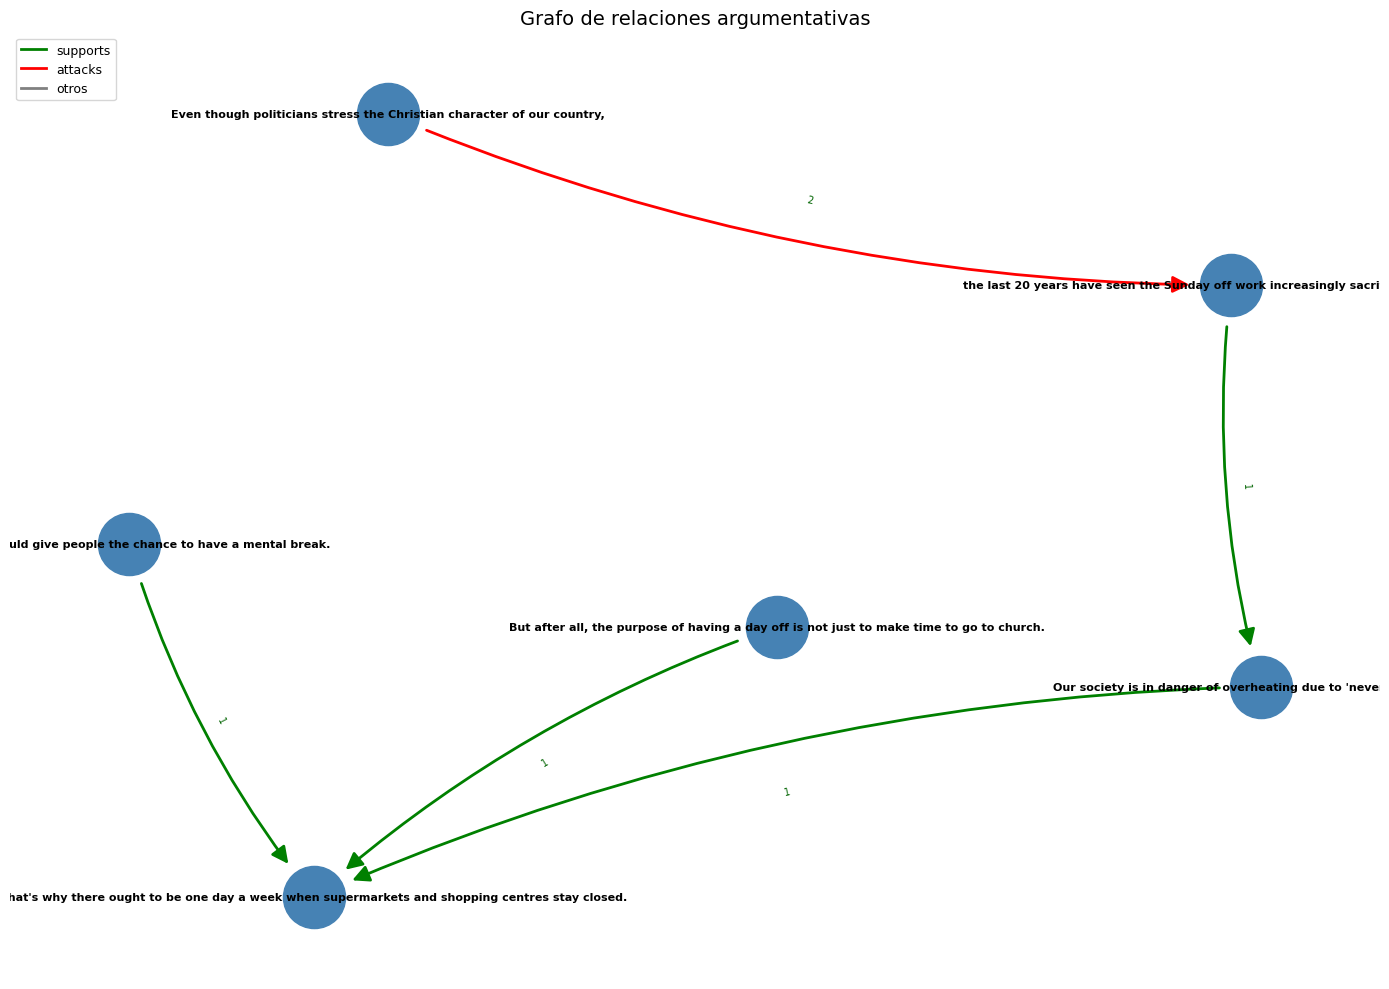

In [136]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Crear grafo dirigido
G = nx.DiGraph()

# Agregar aristas
for _, row in df_resultado_mircro.iterrows():
    G.add_edge(row["proposition_2"], row["proposition_1"], label=row["relations"])

# Colores por tipo de relación
colores_label = {1: "green", 2: "red"}
edge_colors = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]

# ── Graficar ─────────────────────────────────────────────
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42, k=0.5, iterations=10)

# Nodos
nx.draw_networkx_nodes(G, pos, node_color="steelblue", node_size=2000)
nx.draw_networkx_labels(G, pos, font_color="black", font_size=8, font_weight="bold")

# Aristas con flechas
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=25,
    arrowstyle="-|>",          # Estilo de flecha
    width=2,                    # Grosor de línea
    connectionstyle="arc3,rad=0.1",  # Curvatura para ver mejor las flechas
    min_source_margin=30,       # Margen para que la flecha no tape el nodo
    min_target_margin=30,
)

# Etiquetas de aristas
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7,
    font_color="darkgreen"
)

# Leyenda
from matplotlib.lines import Line2D
leyenda = [
    Line2D([0], [0], color="green", linewidth=2, label="supports"),
    Line2D([0], [0], color="red",   linewidth=2, label="attacks"),
    Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
]
plt.legend(handles=leyenda, loc="upper left", fontsize=9)

plt.title("Grafo de relaciones argumentativas", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.show()